In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [ ]:
df = pd.read_csv("onlinefraud.csv")
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


Data Exploratory (EDA)

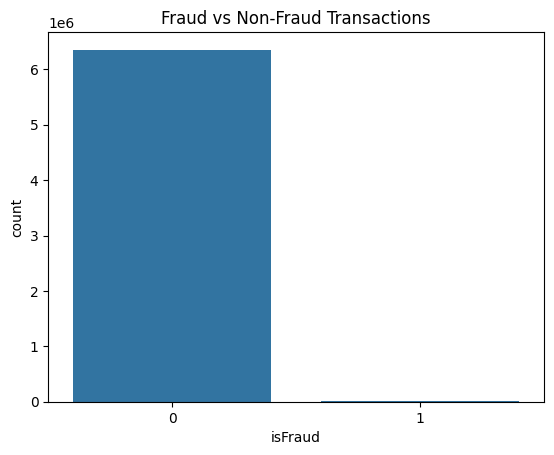

In [ ]:
sns.countplot(x='isFraud', data=df)
plt.title("Fraud vs Non-Fraud Transactions")
plt.show()

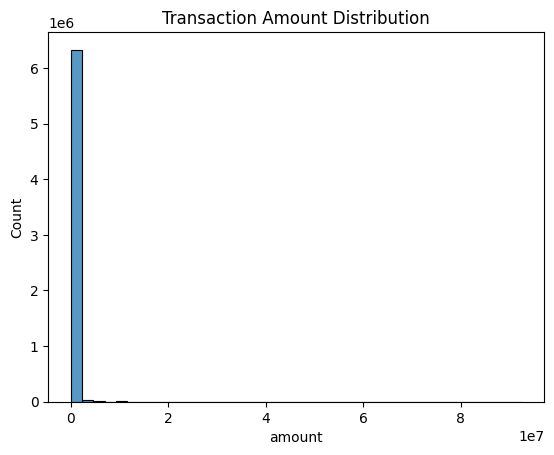

In [ ]:
sns.histplot(df["amount"], bins=40)
plt.title("Transaction Amount Distribution")
plt.show()

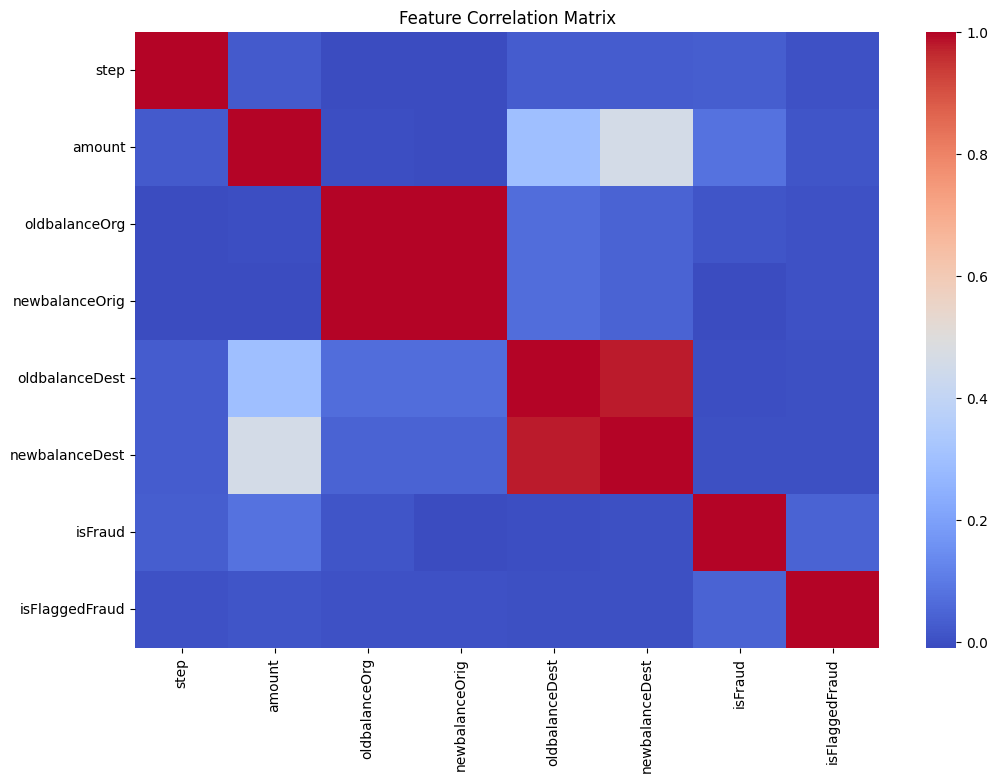

In [ ]:
plt.figure(figsize=(12,8))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), cmap="coolwarm")

plt.title("Feature Correlation Matrix")
plt.show()

Data Cleaning

In [ ]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
df.drop("isFlaggedFraud", axis=1, inplace=True)

In [ ]:
df.drop(['nameOrig', 'nameDest'], axis=1, inplace=True)
df.dropna(inplace=True)

df["Is_All_Out"] = (df["amount"] == df["oldbalanceOrg"]).astype(int)
df["isFraud"] = df["isFraud"].astype(int)

# One-Hot Encoding
df = pd.get_dummies(df, columns=["type"], drop_first=True)

Feature Engineering

In [ ]:
# Feature: High amount + low sender balance risk pattern
df["HighAmt_LowBal"] = (
    (df["amount"] > 200) &
    (df["oldbalanceOrg"] < 2000)
).astype(int)

In [ ]:
pd.crosstab(df["HighAmt_LowBal"], df["isFraud"], normalize='index')


isFraud,0,1
HighAmt_LowBal,,
0,0.997890,0.002110
1,0.999968,0.000032


In [ ]:
df["HighAmt_LowBal"].value_counts()

,count
HighAmt_LowBal,
0,3854532
1,2508088


In [ ]:
df.groupby("HighAmt_LowBal")["isFraud"].mean()

,isFraud
HighAmt_LowBal,
0,0.002110
1,0.000032


In [ ]:
df["isFraud"].isnull().sum()

np.int64(0)

In [ ]:
df = df.dropna(subset=["isFraud"])

In [ ]:
df["isFraud"] = df["isFraud"].astype(int)

Split Dataset

In [ ]:
X = df.drop("isFraud", axis=1)
y = df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
X_train = X_train.drop(columns=['nameOrig', 'nameDest'], errors='ignore')
X_test = X_test.drop(columns=['nameOrig', 'nameDest'], errors='ignore')

Feature Scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
import gc
# Deleting the massive raw dataframes that are eating the RAM
if 'df' in globals(): del df
if 'legit' in globals(): del legit
if 'fraud' in globals(): del fraud

gc.collect()
print("RAM Cleared. Ready for training.")

RAM Cleared. Ready for training.


In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy=0.2, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

In [ ]:
pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(X_train_res)
X_test_pca = pca.transform(X_test_scaled)

In [ ]:
X_train_pca = X_train_pca.astype('float32')
X_test_pca = X_test_pca.astype('float32')

Creating Feature Vector using Autoencoder

In [ ]:
#STEP 1: Data Preparation
X_train_normal = X_train_scaled[y_train == 0]
if len(X_train_normal) > 100000:
    X_train_normal_sub = X_train_normal[:100000]
else:
    X_train_normal_sub = X_train_normal

input_dim = X_train.shape[1]
input_layer = Input(shape=(input_dim,))

#STEP 2: Architecture
encoded = Dense(16, activation='relu')(input_layer)
latent = Dense(8, activation='relu')(encoded)
decoded = Dense(16, activation='relu')(latent)
output_layer = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')

#STEP 3: Training
print("Training Autoencoder on 'Normal' transactions...")
autoencoder.fit(
    X_train_normal_sub, X_train_normal_sub,
    epochs=10,
    batch_size=2048,
    shuffle=True,
    verbose=1
)

#STEP 4: Error Calculation
print("Calculating Reconstruction Errors...")
X_test_pred = autoencoder.predict(X_test_scaled, batch_size=2048)
# Vectorized MSE calculation
mse_test = np.mean(np.square(X_test_scaled - X_test_pred), axis=1)

# same for Train data
X_train_pred = autoencoder.predict(X_train_scaled, batch_size=2048)
mse_train = np.mean(np.square(X_train_scaled - X_train_pred), axis=1)


X_train_final = np.hstack([X_train_scaled, mse_train.reshape(-1, 1)])
X_test_final = np.hstack([X_test_scaled, mse_test.reshape(-1, 1)])

print("Done! You now have an 'Anomaly Score' feature.")

Training Autoencoder on 'Normal' transactions...
Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8618
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6995
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5147
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3308
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2050
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1453
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0997
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0664
Epoch 9/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0483
Epoch 10/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0379
Calculating Reconstruction Errors...
622/622 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
2486/2486 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
Done! You now have an 'Anomaly Score' feature.


Model Training

In [ ]:
# 1. Calculate MSE for the resampled training data
X_train_res_pred = autoencoder.predict(X_train_res, batch_size=2048)
mse_train_res = np.mean(np.square(X_train_res - X_train_res_pred), axis=1)

# 2. Attaching the Anomaly Score to the Training and Testing sets
X_train_combined = np.hstack([X_train_res, mse_train_res.reshape(-1, 1)])
X_test_combined = np.hstack([X_test_scaled, mse_test.reshape(-1, 1)])

lr = LogisticRegression(max_iter=1000, class_weight='balanced', n_jobs=-1)
lr.fit(X_train_combined, y_train_res)

y_pred_lr = lr.predict(X_test_combined)

print("Logistic Regression (SMOTE + Anomaly Score)")
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

2979/2979 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
Logistic Regression (SMOTE + Anomaly Score)
[[1270827      54]
 [      4    1639]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.97      1.00      0.98      1643

    accuracy                           1.00   1272524
   macro avg       0.98      1.00      0.99   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:
X_train_res_pred = autoencoder.predict(X_train_res, batch_size=2048)
mse_train_res = np.mean(np.square(X_train_res - X_train_res_pred), axis=1)
X_train_final = np.hstack([X_train_res, mse_train_res.reshape(-1, 1)])

X_test_pred = autoencoder.predict(X_test_scaled, batch_size=2048)
mse_test = np.mean(np.square(X_test_scaled - X_test_pred), axis=1)
X_test_final = np.hstack([X_test_scaled, mse_test.reshape(-1, 1)])

rf = RandomForestClassifier(
    n_estimators=10,
    max_depth=5,
    max_features=1.0,
    class_weight='balanced',
    n_jobs=1,
    random_state=42,
    verbose=1
)

print("Training Random Forest with Anomaly Scoring...")
rf.fit(X_train_final.astype('float32'), y_train_res)

y_pred_rf = rf.predict(X_test_final)

print("\nRandom Forest Results (SMOTE + Anomaly Score):")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

2979/2979 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
622/622 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Training Random Forest with Anomaly Scoring...


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:  8.5min finished
[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.5s finished



Random Forest Results (SMOTE + Anomaly Score):
[[1270848      33]
 [      4    1639]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      1.00      0.99      1643

    accuracy                           1.00   1272524
   macro avg       0.99      1.00      0.99   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:

dt = DecisionTreeClassifier(
    max_depth=12,
    class_weight='balanced',
    random_state=42
)

print("Training Decision Tree with Anomaly Scoring...")
dt.fit(X_train_final, y_train_res)

y_pred_dt = dt.predict(X_test_final)

print("\nDecision Tree Results (SMOTE + Anomaly Score):")
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Training Decision Tree with Anomaly Scoring...

Decision Tree Results (SMOTE + Anomaly Score):
[[1270638     243]
 [      4    1639]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.87      1.00      0.93      1643

    accuracy                           1.00   1272524
   macro avg       0.94      1.00      0.96   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:
xgb = XGBClassifier(
    scale_pos_weight=1,
    eval_metric='logloss',
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    n_jobs=-1,
    random_state=42
)

print("Training XGBoost with Anomaly Scoring...")
xgb.fit(X_train_final, y_train_res)

y_pred_xgb = xgb.predict(X_test_final)

# 4. Evaluation
print("\nXGBoost Results (SMOTE + Anomaly Score):")
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Training XGBoost with Anomaly Scoring...

XGBoost Results (SMOTE + Anomaly Score):
[[1270789      92]
 [      4    1639]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.95      1.00      0.97      1643

    accuracy                           1.00   1272524
   macro avg       0.97      1.00      0.99   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:
from sklearn.metrics import roc_auc_score

# 1. Logistic Regression
y_prob_lr = lr.predict_proba(X_test_combined)[:, 1]
print(f"LR ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")

# 2. Random Forest
y_prob_rf = rf.predict_proba(X_test_combined)[:, 1]
print(f"RF ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

# 3. Decision Tree
y_prob_dt = dt.predict_proba(X_test_combined)[:, 1]
print(f"DT ROC-AUC: {roc_auc_score(y_test, y_prob_dt):.4f}")

# 4. XGBoost
y_prob_xgb = xgb.predict_proba(X_test_combined)[:, 1]
print(f"XGB ROC-AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}")

LR ROC-AUC: 1.0000


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.9s finished


RF ROC-AUC: 0.9998
DT ROC-AUC: 0.9987
XGB ROC-AUC: 0.9999


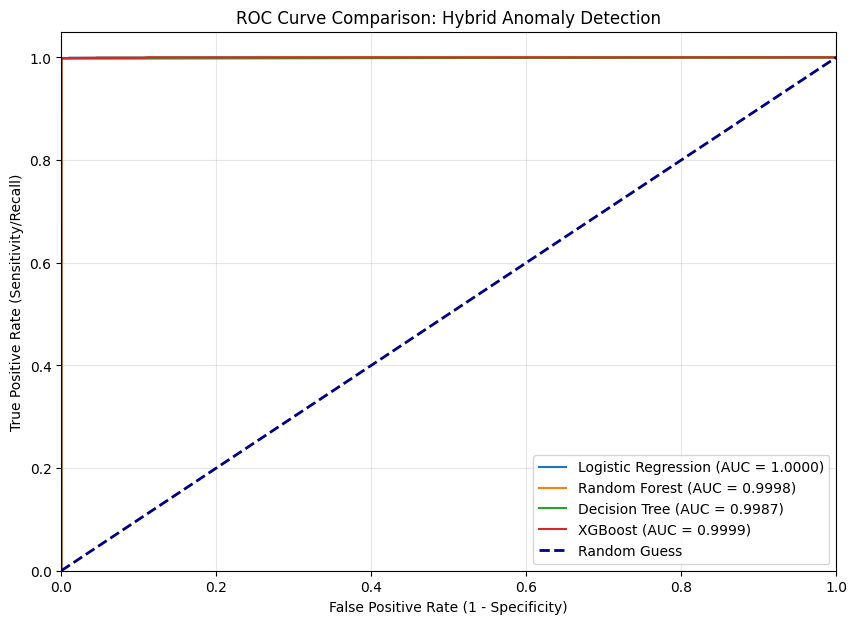

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# 1. Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = auc(fpr_lr, tpr_lr)
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.4f})")

# 2. Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.4f})")

# 3. Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = auc(fpr_dt, tpr_dt)
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.4f})")

# 4. XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb = auc(fpr_xgb, tpr_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.4f})")

# Baseline: The 'Random Guess' line
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity/Recall)")
plt.title("ROC Curve Comparison: Hybrid Anomaly Detection")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.savefig("ROC_Comparison_Final.png", dpi=300)
plt.show()

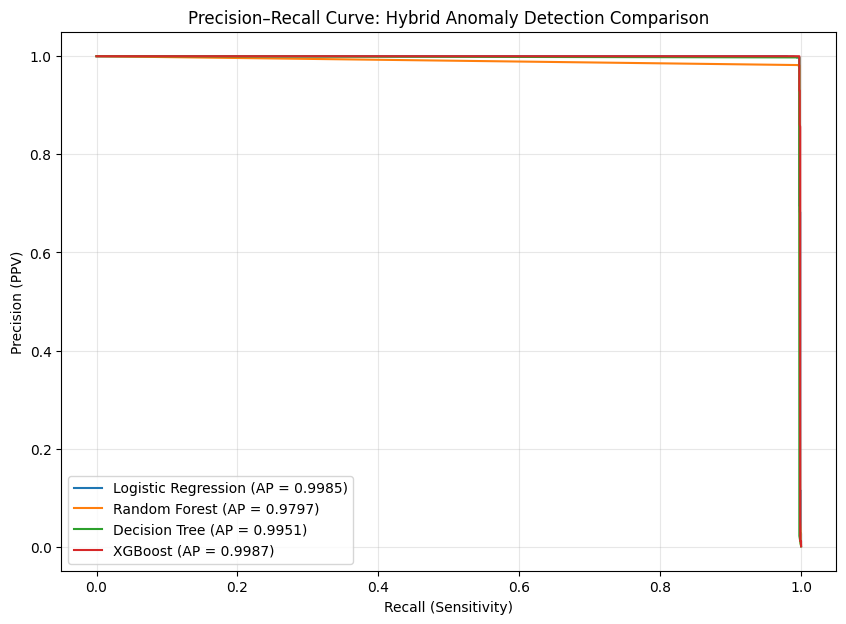

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# 1. Logistic Regression
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
ap_lr = average_precision_score(y_test, y_prob_lr)
plt.plot(recall_lr, precision_lr, label=f"Logistic Regression (AP = {ap_lr:.4f})")

# 2. Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)
ap_rf = average_precision_score(y_test, y_prob_rf)
plt.plot(recall_rf, precision_rf, label=f"Random Forest (AP = {ap_rf:.4f})")

# 3. Decision Tree
precision_dt, recall_dt, _ = precision_recall_curve(y_test, y_prob_dt)
ap_dt = average_precision_score(y_test, y_prob_dt)
plt.plot(recall_dt, precision_dt, label=f"Decision Tree (AP = {ap_dt:.4f})")

# 4. XGBoost
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)
ap_xgb = average_precision_score(y_test, y_prob_xgb)
plt.plot(recall_xgb, precision_xgb, label=f"XGBoost (AP = {ap_xgb:.4f})")

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision (PPV)")
plt.title("Precision–Recall Curve: Hybrid Anomaly Detection Comparison")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.savefig("PR_Comparison_Final.png", dpi=300)
plt.show()

In [ ]:
import joblib

joblib.dump(xgb, "fraud_model.pkl")
joblib.dump(pca, "pca.pkl")
joblib.dump(scaler, "scaler.pkl")
autoencoder.save("autoencoder_model.keras")

In [ ]:
from google.colab import files

files.download("fraud_model.pkl")
files.download("pca.pkl")
files.download("scaler.pkl")
files.download("autoencoder_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>